# INTRODUCTION TO MACHINE LEARNING

- Supervised Learning (in syllabus) -> colname included
    - Regression -> to analyze numerical data
    - Classification -> to analyze objects
- Unsupervised Learning
- Reinforcement Learning

**Feature(columns) Engineering**

In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.DataFrame({"Roll":[1,2,3,4,5],"Student":['A','B','C','D','E'],"FSD-2":[78,87,48,34,83],"Python-2":[56,65,87,75,92],
                 "TOC":[67,34,51,84,84],"COA":[99,34,62,92,95],"DM":[87,95,30,89,89]})
df['Total Marks']=df["FSD-2"]+df["Python-2"]+df["TOC"]+df["COA"]+df["DM"]
df["Percentage"]=df['Total Marks']*100/500
# np.where(condition,true,false)
df["Grade"]=np.where(df["Percentage"]>=80,"Distinction",(np.where(df["Percentage"]<60,"Second Class","First Class")))
df

,Roll,Student,FSD-2,Python-2,TOC,COA,DM,Total Marks,Percentage,Grade
0,1,A,78,56,67,99,87,387,77.4,First Class
1,2,B,87,65,34,34,95,315,63.0,First Class
2,3,C,48,87,51,62,30,278,55.6,Second Class
3,4,D,34,75,84,92,89,374,74.8,First Class
4,5,E,83,92,84,95,89,443,88.6,Distinction


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Roll         5 non-null      int64  
 1   Student      5 non-null      object 
 2   FSD-2        5 non-null      int64  
 3   Python-2     5 non-null      int64  
 4   TOC          5 non-null      int64  
 5   COA          5 non-null      int64  
 6   DM           5 non-null      int64  
 7   Total Marks  5 non-null      int64  
 8   Percentage   5 non-null      float64
 9   Grade        5 non-null      object 
dtypes: float64(1), int64(7), object(2)
memory usage: 532.0+ bytes


In [5]:
df.drop("Student",axis=1,inplace=True)

In [6]:
df

,Roll,FSD-2,Python-2,TOC,COA,DM,Total Marks,Percentage,Grade
0,1,78,56,67,99,87,387,77.4,First Class
1,2,87,65,34,34,95,315,63.0,First Class
2,3,48,87,51,62,30,278,55.6,Second Class
3,4,34,75,84,92,89,374,74.8,First Class
4,5,83,92,84,95,89,443,88.6,Distinction


In [8]:
df=pd.get_dummies(df,drop_first=True) # for categorical data, dropped acc to ascii value
df

,Roll,FSD-2,Python-2,TOC,COA,DM,Total Marks,Percentage,Grade_First Class,Grade_Second Class
0,1,78,56,67,99,87,387,77.4,True,False
1,2,87,65,34,34,95,315,63.0,True,False
2,3,48,87,51,62,30,278,55.6,False,True
3,4,34,75,84,92,89,374,74.8,True,False
4,5,83,92,84,95,89,443,88.6,False,False


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Roll                5 non-null      int64  
 1   FSD-2               5 non-null      int64  
 2   Python-2            5 non-null      int64  
 3   TOC                 5 non-null      int64  
 4   COA                 5 non-null      int64  
 5   DM                  5 non-null      int64  
 6   Total Marks         5 non-null      int64  
 7   Percentage          5 non-null      float64
 8   Grade_Distinction   5 non-null      bool   
 9   Grade_First Class   5 non-null      bool   
 10  Grade_Second Class  5 non-null      bool   
dtypes: bool(3), float64(1), int64(7)
memory usage: 467.0 bytes


In [10]:
ol=pd.read_csv('olympic100m.csv')

In [17]:
ol.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    29 non-null     int64  
 1   time    29 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 596.0 bytes


In [13]:
#QUE. Predict the time in 2032

In [14]:
import sklearn  #To install--> pip install sci-kit learn

In [18]:
# x = dependent quantity EXPECTS DATAFRAME ALWAYS
# y ALWAYS in SERIES (that is to be predicted)

In [26]:
x=ol[['year']] # to convert series into DataFrame
y=ol['time']
# x2=ol['year']
# x3=np.array(x2).reshape((1,-1))
type(x)

pandas.core.frame.DataFrame

In [25]:
from sklearn.linear_model import LinearRegression

In [27]:
model=LinearRegression()
model.fit(x,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
y_pred=model.predict(x)

In [30]:
y_pred

array([11.12455601, 11.07301534, 11.02147467, 10.99570434, 10.969934  ,
       10.91839333, 10.81531199, 10.76377132, 10.71223065, 10.66068998,
       10.60914931, 10.45452731, 10.40298664, 10.35144597, 10.2999053 ,
       10.24836463, 10.19682396, 10.14528329, 10.09374262, 10.04220195,
        9.99066128,  9.93912061,  9.88757994,  9.83603927,  9.7844986 ,
        9.73295793,  9.68141726,  9.62987659,  9.57833592])

In [31]:
import matplotlib.pyplot as plt

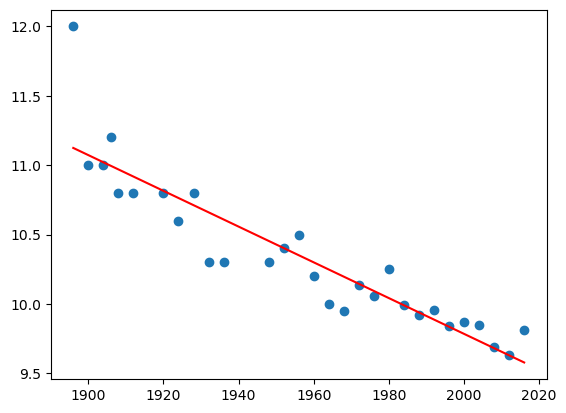

In [35]:
plt.scatter(x,y)
plt.plot(x,y_pred,color="Red")
plt.show()

In [38]:
y_2032=model.predict([[2032]])
y_2032

C:\Users\LJENG\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([9.37217324])

In [39]:
car=pd.read_csv("car data.csv")

In [40]:
car.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [41]:
car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [43]:
car.drop(columns=["Car_Name","Seller_Type","Owner"],axis=1,inplace=True)
car

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Transmission
0,2014,3.35,5.59,27000,Petrol,Manual
1,2013,4.75,9.54,43000,Diesel,Manual
2,2017,7.25,9.85,6900,Petrol,Manual
3,2011,2.85,4.15,5200,Petrol,Manual
4,2014,4.60,6.87,42450,Diesel,Manual
...,...,...,...,...,...,...
296,2016,9.50,11.60,33988,Diesel,Manual
297,2015,4.00,5.90,60000,Petrol,Manual
298,2009,3.35,11.00,87934,Petrol,Manual
299,2017,11.50,12.50,9000,Diesel,Manual


In [44]:
car=pd.get_dummies(car,drop_first=True)
car

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Manual
0,2014,3.35,5.59,27000,False,True,True
1,2013,4.75,9.54,43000,True,False,True
2,2017,7.25,9.85,6900,False,True,True
3,2011,2.85,4.15,5200,False,True,True
4,2014,4.60,6.87,42450,True,False,True
...,...,...,...,...,...,...,...
296,2016,9.50,11.60,33988,True,False,True
297,2015,4.00,5.90,60000,False,True,True
298,2009,3.35,11.00,87934,False,True,True
299,2017,11.50,12.50,9000,True,False,True


In [50]:
y=car["Selling_Price"]
x=car.drop("Selling_Price",axis=1)

In [52]:
x

,Year,Present_Price,Kms_Driven,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Manual
0,2014,5.59,27000,False,True,True
1,2013,9.54,43000,True,False,True
2,2017,9.85,6900,False,True,True
3,2011,4.15,5200,False,True,True
4,2014,6.87,42450,True,False,True
...,...,...,...,...,...,...
296,2016,11.60,33988,True,False,True
297,2015,5.90,60000,False,True,True
298,2009,11.00,87934,False,True,True
299,2017,12.50,9000,True,False,True


# SPLIT DATA to TRAIN & TEST

In [53]:
# SPLIT when sample size>50
from sklearn.model_selection import train_test_split
# first var for Train 

In [76]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=10)

In [77]:
x_train.shape # by default=75%

(240, 6)

In [78]:
x_test.shape

(61, 6)

In [80]:
y_test # to net get randomness after rerunning, use random_state

258     8.40
154     0.50
227     2.55
126     0.90
268     4.80
       ...  
275    10.90
121     1.05
231     9.25
299    11.50
281     2.10
Name: Selling_Price, Length: 61, dtype: float64

In [82]:
model=LinearRegression()
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [83]:
y_pred=model.predict(x_test)

In [84]:
y_pred

array([ 7.46764389,  1.40745791,  1.19699337,  2.72159035,  4.72878936,
        6.58660085, 20.07989003, -1.98741644,  1.64098728,  3.862693  ,
        0.62430362,  8.77884801,  3.81118258, -0.40555769,  5.61498897,
        2.86645002,  3.95078357, -6.98571384,  1.98325801,  5.37240579,
        2.69175503,  2.68335664,  6.46389673, 21.87048274,  0.23938375,
        1.66912836, -0.73509045, -1.27855643,  2.17784223, -2.94607878,
       -1.02596276, 14.12172145,  4.03520512,  7.51131194,  0.59672799,
        6.44036309,  1.95824402,  2.9857931 ,  2.30899907,  3.64979513,
        5.21111983,  0.91393229,  6.26009018,  0.29057747, 10.52757867,
        2.81359129, -0.2630699 ,  4.32398672,  8.72389645,  2.4829894 ,
       -0.65429831,  5.92126988,  1.50107766,  9.80581299,  4.17990047,
        3.93813863,  8.61413712,  0.51881533,  6.45107455, 10.00698344,
        0.76982633])

In [88]:
y_sell=model.predict([[2030,11,20000,1,0,0]])

C:\Users\LJENG\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [89]:
y_sell

array([15.15064141])